# Persian Spotify Analysis
Alright, listen up folks! We're about to dive into some serious data analysis and machine learning. We'll start with some EDA to get to know the data, and then we'll use machine learning to extract some juicy insights. So, let's not waste any time and get this journey started!

# Persian Spotify Analysis

Exploratory data analysis and machine learning on Persian artists on Spotify.


# Import Libraries

In [44]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn import metrics
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix
)
from pprint import pprint 

In [45]:
%pwd

'c:\\Users\\ASUS\\Desktop\\DM_final_project_9831112'

# Load Spotify Dataset (CSV file)

In [46]:
spotify_df = pd.read_csv("Spotfiy_Persian_Artists.csv")
spotify_df.describe()

,disc_number,duration_ms,popularity,track_number,album_total_tracks,album_release_year,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,10632.000000,1.063200e+04,931.000000,10632.000000,931.000000,10632.000000,10632.000000,10632.000000,10632.000000,10632.000000,10632.000000,10632.000000,10632.000000,10632.000000,10632.000000,10632.000000,10632.000000,10632.000000
mean,1.069225,2.888011e+05,20.113856,5.576279,9.707841,1981.687453,0.510869,0.496408,5.205982,-10.070847,0.373965,0.069843,0.609586,0.127399,0.193231,0.450537,119.381223,3.666384
std,0.386374,1.695220e+05,10.415865,4.533367,6.744375,232.376793,0.172341,0.241768,3.635221,4.605740,0.483877,0.071078,0.317795,0.284277,0.154764,0.239068,29.831699,0.637143
min,1.000000,3.996000e+03,0.000000,1.000000,1.000000,0.000000,0.000000,0.000975,0.000000,-37.404000,0.000000,0.000000,0.000022,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,2.035690e+05,13.000000,2.000000,5.000000,2005.000000,0.372000,0.298000,2.000000,-12.665750,0.000000,0.036100,0.332000,0.000000,0.095800,0.256750,95.114750,3.000000
50%,1.000000,2.536180e+05,20.000000,5.000000,10.000000,2010.000000,0.497000,0.489000,5.000000,-9.067000,0.000000,0.044900,0.725000,0.000088,0.133000,0.421000,120.076000,4.000000
75%,1.000000,3.337745e+05,28.000000,8.000000,12.000000,2016.000000,0.652000,0.693000,9.000000,-6.617750,1.000000,0.067225,0.882000,0.014900,0.250000,0.633000,138.032000,4.000000
max,4.000000,3.978450e+06,48.000000,32.000000,55.000000,2020.000000,0.964000,0.998000,11.000000,-0.626000,1.000000,0.939000,0.996000,0.995000,0.992000,0.980000,219.960000,5.000000


# EDA

Exploratory Data Analysis (EDA) is a crucial step in the data analysis process. It helps us to better understand the given data, so that we can make sense out of it. If EDA is not done properly, it can hamper the further steps in the machine learning model building process. On the other hand, if done well, it may improve the efficacy of everything we do next. In order to perform EDA, we need to follow a systematic approach that involves several techniques. The following are some of the key steps involved in EDA:

1. Data Sourcing: This is the very first step of EDA, where we access data and load it into our system.

2. Data Cleaning: Once we have the data, we need to clean it by removing any inconsistencies, missing values, or outliers.

3. Univariate Analysis: In this step, we analyze each variable in isolation to understand its distribution, central tendency, and spread.

4. Bivariate Analysis: Here, we analyze the relationship between two variables to understand how they are related to each other.

5. Multivariate Analysis: This step involves analyzing the relationship between multiple variables to understand how they are related to each other.

By conducting EDA, we can turn an almost unusable dataset into a completely usable one. EDA helps to clean up a dataset and gives us a better understanding of the variables and the relationships between them. It is a creative process that involves generating questions about the data, searching for answers by visualizing, transforming, and modeling the data, and using what we learn to refine our questions and/or generate new ones.


In this section, we want to explore a bit dataset characteristics. To do so, you will answer specified questions below.

In [47]:
spotify_df.head()

,track_id,disc_number,duration_ms,explicit,track_name,track_name_farsi,artist_name,artist_name_farsi,popularity,track_number,...,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,key_name,mode_name,key_mode
0,31iPeC6I0AiRW8InOxNKzm,1,446880,False,Ghazale Taze,NaN,Salar Aghili,سالار عقیلی,NaN,1,...,0.0299,0.839,0.000035,0.1360,0.330,131.913,3,C,minor,C minor
1,4Fi46ha8teWYTwk0b8fNPi,1,851920,False,Ayeeneye Hosn,NaN,Salar Aghili,سالار عقیلی,NaN,2,...,0.0414,0.970,0.000360,0.0812,0.346,105.634,4,F,major,F major
2,0lQAe6EslKA7CUsS7SCW6Q,1,293160,False,Tarke Eshgh,NaN,Salar Aghili,سالار عقیلی,NaN,3,...,0.0349,0.664,0.002070,0.1100,0.501,94.651,5,F,minor,F minor
3,6dAFmJdVsKk5ksCpGqnKgO,1,648720,False,Moghbacheye Bade Foroosh,NaN,Salar Aghili,سالار عقیلی,NaN,4,...,0.0451,0.915,0.006580,0.2120,0.445,110.967,5,D,minor,D minor
4,4VSDJGyEdSMB8UL4fDSCvv,1,273480,False,Bigharar,NaN,Salar Aghili,سالار عقیلی,NaN,5,...,0.0334,0.657,0.000008,0.1200,0.410,148.053,1,C,minor,C minor


In [48]:
spotify_df.columns

Index(['track_id', 'disc_number', 'duration_ms', 'explicit', 'track_name',
       'track_name_farsi', 'artist_name', 'artist_name_farsi', 'popularity',
       'track_number', 'album_href', 'album_id', 'album_name',
       'album_release_date', 'album_total_tracks', 'album_release_year',
       'track_href', 'danceability', 'energy', 'key', 'loudness', 'mode',
       'speechiness', 'acousticness', 'instrumentalness', 'liveness',
       'valence', 'tempo', 'time_signature', 'key_name', 'mode_name',
       'key_mode'],
      dtype='object')

## Q: Get number of songs by each of the artists in descending order

In [49]:
# if we find the number of singers occurance in dataset we can find out how many songs are there for each singer in the dataset 
unique_tracks = spotify_df.drop_duplicates(subset=["track_name"], keep=False)
number_of_songs = unique_tracks['artist_name'].value_counts()
number_of_songs

artist_name
Hossein Alizadeh          452
Salar Aghili              341
Alireza Eftekhari         340
Mohammadreza Shajarian    298
Reza Sadeghi              280
                         ... 
Mohammad Golriz            16
Macan Band                  8
Farman Fathalian            6
Koveyti Poor                6
Xaniar Khosravi             5
Name: count, Length: 69, dtype: int64

## Q: Get the average duration of songs by each of the artists in minutes

In [50]:
# Calculate mean duration in seconds for each artist
mean_durations = spotify_df.groupby('artist_name')['duration_ms'].mean().reset_index()

# Convert mean duration to minutes and store in a separate column
mean_durations['duration_minutes'] = mean_durations['duration_ms'] / 1000 / 60

# Combine mean_durations and mean_durations_in_minutes into a list of tuples
combined_means = list(zip(mean_durations['duration_ms'].tolist(), mean_durations['duration_minutes'].tolist()))

print(mean_durations)

              artist_name    duration_ms  duration_minutes
0           Abbas Ghaderi  304482.300000          5.074705
1   Abdolhosein Mokhtabad  373726.169811          6.228769
2        Afshin Moghaddam  246046.791667          4.100780
3            Ali Lohrasbi  216124.748466          3.602079
4         Ali Zand Vakili  291287.171717          4.854786
..                    ...            ...               ...
64      Siavash Ghomayshi  260494.891753          4.341582
65        Sirvan Khosravi  261151.736364          4.352529
66         Soheil Nafissi  183814.826087          3.063580
67                   Tohi  211404.468750          3.523408
68        Xaniar Khosravi  236043.909091          3.934065

[69 rows x 3 columns]


## Q: list of artist's unique names

In [51]:
# key values of number of songs dictionary 
number_of_songs.keys()

Index(['Hossein Alizadeh', 'Salar Aghili', 'Alireza Eftekhari',
       'Mohammadreza Shajarian', 'Reza Sadeghi', 'Shahram Nazeri',
       'Homayoun Shajarian', 'Dariush', 'Sattar', 'Moein', 'Mohsen Chavoshi',
       'Alireza Ghorbani', 'Parviz Meshkatian', 'Amir Tataloo',
       'Ali Zand Vakili', 'Peyman Yazdanian', 'Mohammad Nouri',
       'Mohsen Namjoo', 'Farzad Farzin', 'Shahram Shabpareh',
       'Hassan Shamaizadeh', 'Siavash Ghomayshi', 'Abbas Ghaderi',
       'Mohammad Esfahani', 'Benyamin Bahadori', 'Majid Akhshabi',
       'Sirvan Khosravi', 'Hesameddin Seraj', 'Abdolhosein Mokhtabad',
       'Mohsen Yeganeh', 'Faramarz Aslani', 'Mohsen Sharifian',
       'Shahram Shokoohi', 'Kourosh Yaghmaei', 'Ali Lohrasbi', 'Alireza Assar',
       'Mohammad Alizadeh', 'Babak Jahanbakhsh', 'Hamid Askari', 'Hichkas',
       'Dang Show', 'Mehdi Yarrahi', 'Mazyar Fallahi', 'Ehsan Khajeh Amiri',
       'Kaveh Deylami', 'Kayhan Kalhor', 'Amirabbas Golab', 'Javad Yassari',
       'Morteza Pashae

## Q: Plot average duration of tracks by year

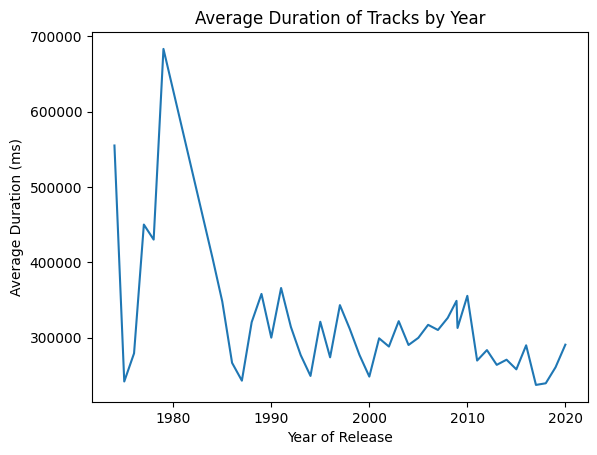

In [52]:
# Replace the zero values in the album_release_year column with the mean of the non-zero values
year_column = spotify_df['album_release_year']
year_column.replace(to_replace=0, value=year_column[year_column != 0].mean(), inplace=True)

# Calculate the mean duration of tracks based on year
mean_duration_by_year = spotify_df.groupby('album_release_year')['duration_ms'].mean().reset_index()

# Plot the average duration of tracks by year
plt.plot(mean_duration_by_year['album_release_year'], mean_duration_by_year['duration_ms'])
plt.title("Average Duration of Tracks by Year")
plt.xlabel('Year of Release')
plt.ylabel('Average Duration (ms)')
plt.show()  

## Q: Plot average loudness of tracks by year

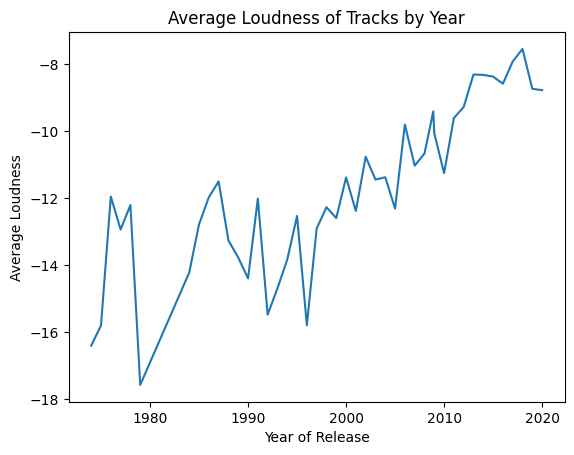

In [53]:
# Replace the zero values in the album_release_year column with the mean of the non-zero values
year_column = spotify_df['album_release_year']
year_column.replace(to_replace=0, value=year_column[year_column != 0].mean(), inplace=True)

# Calculate the mean loudness of tracks based on year
mean_loudness_by_year = spotify_df.groupby('album_release_year')['loudness'].mean().reset_index()

# Plot the average loudness of tracks by year
plt.plot(mean_loudness_by_year['album_release_year'], mean_loudness_by_year['loudness'])
plt.title("Average Loudness of Tracks by Year")
plt.xlabel('Year of Release')
plt.ylabel('Average Loudness')
plt.show()

## Q: Music attributes of songs over the years


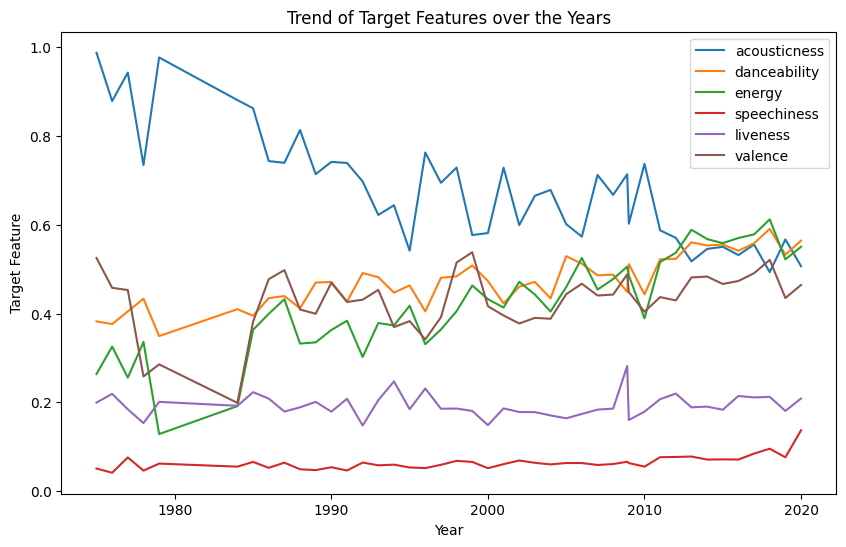

In [54]:
# the columns that we are interseted in
target_cols = ["acousticness","danceability","energy","speechiness","liveness","valence"]

# Calculate the mean of target_cols based on the album release year
mean_target_by_year = spotify_df.groupby('album_release_year')[target_cols].mean().reset_index()

# Plot the trend of target features over the years
plt.figure(figsize=(10, 6))
for col in target_cols:
    plt.plot(mean_target_by_year['album_release_year'][1:], mean_target_by_year[col][1:], label=col)
plt.xlabel('Year')
plt.ylabel('Target Feature')
plt.title('Trend of Target Features over the Years')
plt.legend()
plt.show()

## Q: Plot top 10 popular tracks (Bar Chart)

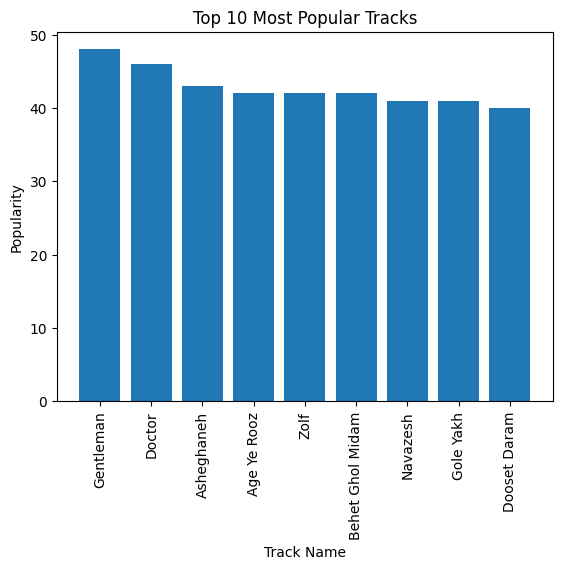

In [55]:
# Replace missing values in the popularity column with the mean of the non-missing values
spotify_df['popularity'].fillna(spotify_df['popularity'].mean(), inplace=True)

# Sort the dataframe by popularity in descending order
spotify_df.sort_values("popularity", ascending=False, inplace=True)

# Get the top 10 most popular tracks and their popularity scores
top10_tracks = spotify_df['track_name'].head(10).tolist()
top10_popularity = spotify_df['popularity'].head(10).tolist()

# Plot a bar graph of the top 10 most popular tracks and their popularity scores
plt.bar(top10_tracks, top10_popularity)
plt.xticks(rotation = 90)
plt.title('Top 10 Most Popular Tracks')
plt.xlabel('Track Name')
plt.ylabel('Popularity')
plt.show()

## Q: Plot top 10 popular artist (Bar Chart)

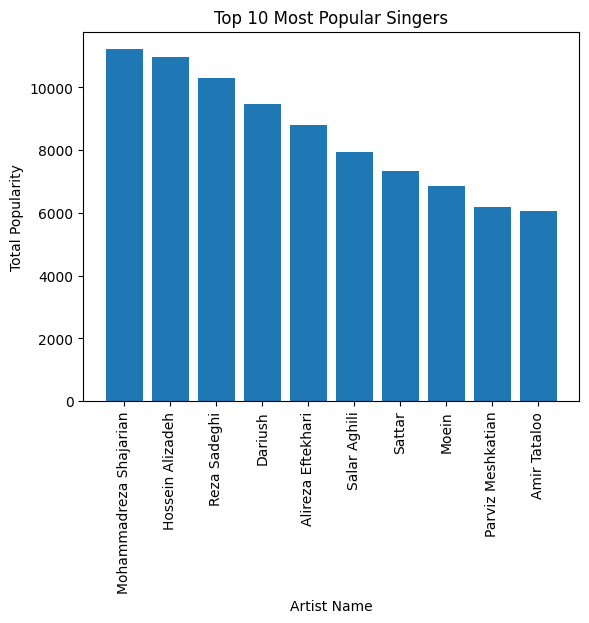

In [56]:
# Calculate the total popularity of each artist
popularity_of_artists = spotify_df.groupby('artist_name')['popularity'].sum().reset_index()

# Sort the artists by total popularity in descending order and get the top 10
popularity_of_artists = popularity_of_artists.sort_values('popularity', ascending=False).head(10)

# Get the names of the top 10 artists
top10_singers = popularity_of_artists['artist_name'].tolist()

# Plot a bar graph of the top 10 most popular singers and their total popularity scores
plt.bar(top10_singers, popularity_of_artists['popularity'])
plt.xticks(rotation = 90)
plt.title('Top 10 Most Popular Singers')
plt.xlabel('Artist Name')
plt.ylabel('Total Popularity')
plt.show()


## Q: Plot correlation matrix's heatmap
What are the most correlated features with `duration_ms` and `popularity`?

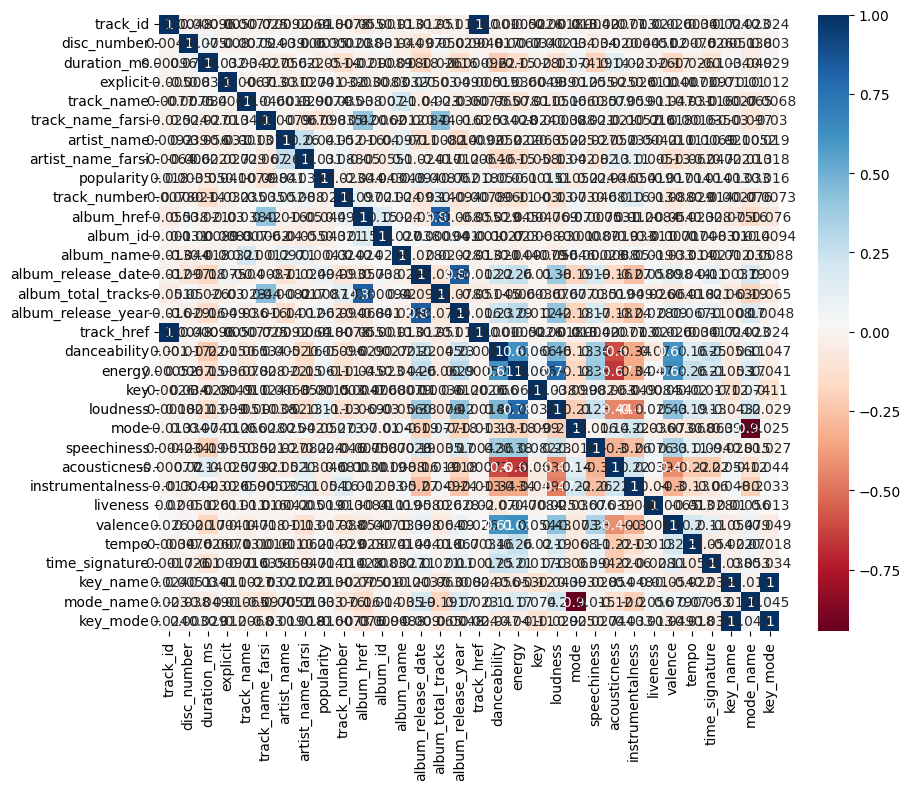

In [57]:
# Convert categorical features to numerical using LabelEncoder
from sklearn.preprocessing import LabelEncoder
lspotify_df = spotify_df
lspotify_df = lspotify_df.apply(LabelEncoder().fit_transform)
plt.figure(figsize=(10, 8))
# Plot a heatmap of the correlation matrix of the numeric features
sns.heatmap(lspotify_df.corr(), cmap = 'RdBu', annot = True)
plt.show()

In [58]:
# duration_ms most to least correlation
correlation_duration = lspotify_df[lspotify_df.columns[0:]].corr()['duration_ms'][:]
from_most_to_least_correlation_duration = correlation_duration.sort_values(ascending = False)
print(from_most_to_least_correlation_duration)

# popularity most to least correlation
correlation_popularity = lspotify_df[lspotify_df.columns[0:]].corr()['popularity'][:]
from_most_to_least_correlation_popularity = correlation_popularity.sort_values(ascending = False)
print(from_most_to_least_correlation_popularity)

duration_ms           1.000000
acousticness          0.138251
disc_number           0.075265
mode                  0.074447
track_name            0.034466
key_name              0.034002
explicit              0.032014
key_mode              0.028555
instrumentalness      0.022798
artist_name_farsi     0.021565
track_href            0.000962
track_id              0.000962
album_id             -0.000889
album_name           -0.018116
album_href           -0.021201
liveness             -0.025824
album_total_tracks   -0.026206
tempo                -0.026415
track_name_farsi     -0.026785
key                  -0.027883
mode_name            -0.049051
popularity           -0.049738
artist_name          -0.056252
time_signature       -0.100253
loudness             -0.128744
track_number         -0.141421
energy               -0.151522
album_release_year   -0.157697
valence              -0.170235
album_release_date   -0.181390
speechiness          -0.193816
danceability         -0.216290
Name: du

## Q: Plot box-plot for each feature 
Compare box-plot values of `energy` and `liveness`

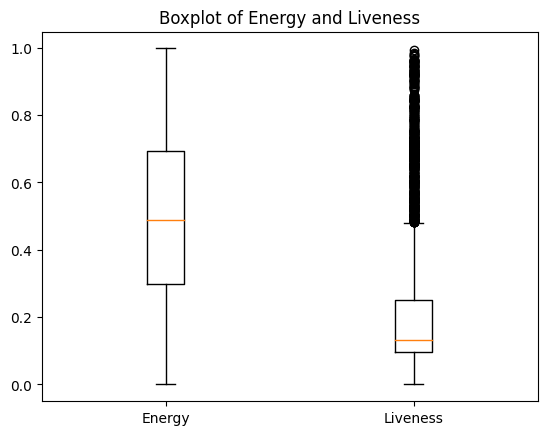

In [59]:
# Create a boxplot of "energy" and "liveness" features
fig, ax = plt.subplots()
ax.boxplot([spotify_df['energy'], spotify_df['liveness']])
ax.set_xticklabels(['Energy', 'Liveness'])
ax.set_title('Boxplot of Energy and Liveness')
plt.show()

## Q: Missing values 
How many `nan` values are there in each column?

In [60]:
spotify_df = pd.read_csv("Spotfiy_Persian_Artists.csv")

# Create a copy of spotify_df and count the number of missing values in each column
df_copy = spotify_df.copy()
nan_count = df_copy.isnull().sum()

# Print the number of missing values in each column
print(nan_count)

track_id                  0
disc_number               0
duration_ms               0
explicit                  0
track_name                0
track_name_farsi      10020
artist_name               0
artist_name_farsi         0
popularity             9701
track_number              0
album_href             9701
album_id                  0
album_name                0
album_release_date        0
album_total_tracks     9701
album_release_year        0
track_href                0
danceability              0
energy                    0
key                       0
loudness                  0
mode                      0
speechiness               0
acousticness              0
instrumentalness          0
liveness                  0
valence                   0
tempo                     0
time_signature            0
key_name                144
mode_name               144
key_mode                144
dtype: int64


# Handling nan values of dataframe
- Fill categorical features with "None"
- Fill numerical features with appropriate approach(mean, median or any imputation). Explain your choice.

In [61]:
spotify_df = pd.read_csv("Spotfiy_Persian_Artists.csv")
# Create a copy of spotify_df and count the number of missing values in each column
df_copy = spotify_df.copy()

columns = df_copy.columns
numerical_cols = df_copy._get_numeric_data().columns

categorical_columns = list(set(columns) - set(numerical_cols))

# fill categorical columns with none
df_copy[categorical_columns] = df_copy[categorical_columns].replace(np.nan, None)



In [62]:
# Fill missing values in numerical features with the mean
numerical_cols = df_copy.select_dtypes(include=['float64']).columns
df_copy[numerical_cols] = df_copy[numerical_cols].fillna(df_copy[numerical_cols].mean())
df_copy.drop_duplicates(subset = ['track_name'], inplace = True)
df_copy

,track_id,disc_number,duration_ms,explicit,track_name,track_name_farsi,artist_name,artist_name_farsi,popularity,track_number,...,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,key_name,mode_name,key_mode
0,31iPeC6I0AiRW8InOxNKzm,1,446880,False,Ghazale Taze,None,Salar Aghili,سالار عقیلی,20.113856,1,...,0.0299,0.839,0.000035,0.1360,0.3300,131.913,3,C,minor,C minor
1,4Fi46ha8teWYTwk0b8fNPi,1,851920,False,Ayeeneye Hosn,None,Salar Aghili,سالار عقیلی,20.113856,2,...,0.0414,0.970,0.000360,0.0812,0.3460,105.634,4,F,major,F major
2,0lQAe6EslKA7CUsS7SCW6Q,1,293160,False,Tarke Eshgh,None,Salar Aghili,سالار عقیلی,20.113856,3,...,0.0349,0.664,0.002070,0.1100,0.5010,94.651,5,F,minor,F minor
3,6dAFmJdVsKk5ksCpGqnKgO,1,648720,False,Moghbacheye Bade Foroosh,None,Salar Aghili,سالار عقیلی,20.113856,4,...,0.0451,0.915,0.006580,0.2120,0.4450,110.967,5,D,minor,D minor
4,4VSDJGyEdSMB8UL4fDSCvv,1,273480,False,Bigharar,None,Salar Aghili,سالار عقیلی,20.113856,5,...,0.0334,0.657,0.000008,0.1200,0.4100,148.053,1,C,minor,C minor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10627,4pEbf7VQrO4StzbqdFOnr5,1,397505,False,Zarbie Bayat Tork (Che Danestam),None,Shahram Nazeri,شهرام ناظري,20.113856,19,...,0.0452,0.946,0.005460,0.3530,0.3960,146.591,5,E,minor,E minor
10628,6umKGf6TO7aRXvJWkP6WSy,1,3522173,False,Conserte Asatid,None,Shahram Nazeri,شهرام ناظري,20.113856,1,...,0.0690,0.982,0.061400,0.6670,0.1610,72.379,3,F,minor,F minor
10629,5KiMQApCqUVNObTO004MWI,1,3402706,False,Soofi Nameh,None,Shahram Nazeri,شهرام ناظري,20.113856,1,...,0.0350,0.883,0.019400,0.2630,0.1390,86.645,4,G#,major,G# major
10630,4w1VKm2kjmA2Xz4YSMBfIn,1,3342733,False,Saghi Nameh,None,Shahram Nazeri,شهرام ناظري,20.113856,1,...,0.0369,0.842,0.223000,0.7980,0.2100,77.819,3,G#,major,G# major


# Determine your desired features here

In [63]:
music_feature_cols = [
 "popularity","acousticness","danceability","energy","speechiness","liveness","valence"
 ]

In [64]:
tracks_feature_df = df_copy[music_feature_cols + ['artist_name']].dropna()
tracks_feature_df

,popularity,acousticness,danceability,energy,speechiness,liveness,valence,artist_name
0,20.113856,0.839,0.437,0.390,0.0299,0.1360,0.3300,Salar Aghili
1,20.113856,0.970,0.379,0.146,0.0414,0.0812,0.3460,Salar Aghili
2,20.113856,0.664,0.437,0.453,0.0349,0.1100,0.5010,Salar Aghili
3,20.113856,0.915,0.488,0.138,0.0451,0.2120,0.4450,Salar Aghili
4,20.113856,0.657,0.301,0.443,0.0334,0.1200,0.4100,Salar Aghili
...,...,...,...,...,...,...,...,...
10627,20.113856,0.946,0.356,0.499,0.0452,0.3530,0.3960,Shahram Nazeri
10628,20.113856,0.982,0.318,0.163,0.0690,0.6670,0.1610,Shahram Nazeri
10629,20.113856,0.883,0.213,0.218,0.0350,0.2630,0.1390,Shahram Nazeri
10630,20.113856,0.842,0.242,0.304,0.0369,0.7980,0.2100,Shahram Nazeri


## Feature Preprocessing
In this section, you should preprocess desired features to get suitable for using in machine learning models. 

In [65]:
# first we take care of Nan and 0 values of popularity feature and we drop the duplicates
tracks_feature_nans = tracks_feature_df.isna().sum()
popularity_column = tracks_feature_df['popularity']
popularity_column.replace(to_replace = 0, value = popularity_column.mean(), inplace = True)




# then we normalize the dataset 
ss = StandardScaler()
tracks_feature_df.iloc[:, : -1] = ss.fit_transform(tracks_feature_df.iloc[:, : -1])

tracks_feature_df

,popularity,acousticness,danceability,energy,speechiness,liveness,valence,artist_name
0,0.003741,0.680472,-0.382308,-0.369615,-0.541516,-0.354279,-0.452846,Salar Aghili
1,0.003741,1.093817,-0.723813,-1.379912,-0.383001,-0.709518,-0.385946,Salar Aghili
2,0.003741,0.128295,-0.382308,-0.108760,-0.472597,-0.522823,0.262148,Salar Aghili
3,0.003741,0.920275,-0.082019,-1.413036,-0.332000,0.138389,0.027998,Salar Aghili
4,0.003741,0.106208,-1.183078,-0.150166,-0.493273,-0.457999,-0.118346,Salar Aghili
...,...,...,...,...,...,...,...,...
10627,0.003741,1.018090,-0.859237,0.081706,-0.330621,1.052417,-0.176883,Shahram Nazeri
10628,0.003741,1.131680,-1.082982,-1.309522,-0.002562,3.087913,-1.159477,Shahram Nazeri
10629,0.003741,0.819306,-1.701223,-1.081791,-0.471218,0.468995,-1.251464,Shahram Nazeri
10630,0.003741,0.689938,-1.530471,-0.725703,-0.445029,3.937117,-0.954596,Shahram Nazeri


## Visualize Dataset Features using Dimension Reduction models (e.g. PCA)

(7586, 2)


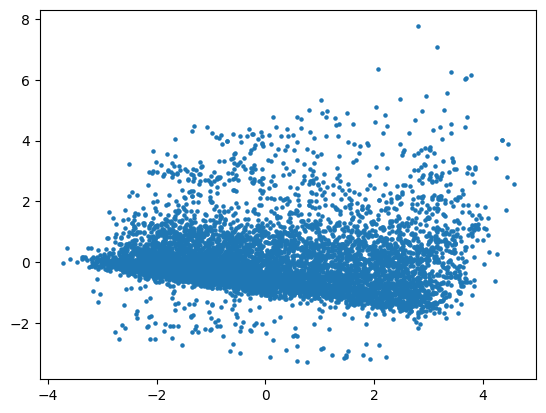

In [66]:
pca = PCA(n_components=2)
tracks_feature_visual = pca.fit_transform(tracks_feature_df.drop(['artist_name'], axis=1))
print(tracks_feature_visual.shape)
plt.scatter(tracks_feature_visual[:, 0], tracks_feature_visual[:, 1], s=5)

(7586, 3)


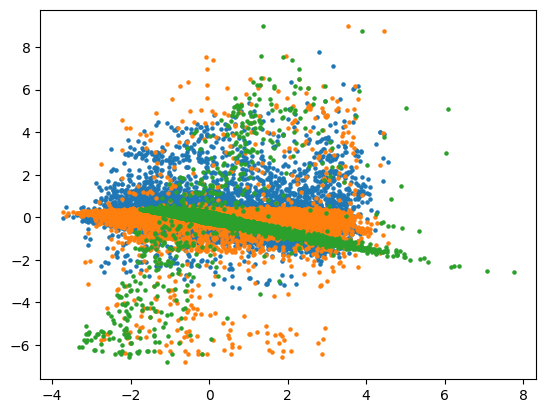

In [67]:
pca = PCA(n_components=3)
tracks_feature_visual = pca.fit_transform(tracks_feature_df.drop(['artist_name'], axis=1))
print(tracks_feature_visual.shape)
plt.scatter(tracks_feature_visual[:, 0], tracks_feature_visual[:, 1], s=5)
plt.scatter(tracks_feature_visual[:, 0], tracks_feature_visual[:, 2], s=5)
plt.scatter(tracks_feature_visual[:, 1], tracks_feature_visual[:, 2], s=5)

## Regression

In [68]:
# Set random seed to make results reproducible 
RANDOM_SEED = 42

In [69]:
df = df_copy
regression_features = [
    "danceability", "energy", "key", "loudness", "mode", "speechiness", "acousticness", "instrumentalness", "duration_ms"
]
x=df.loc[:, regression_features].values
y=df.loc[:,'popularity'].values



x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=RANDOM_SEED)

In this section, you should use `LinearRegression` class in scikit-learn library to implement regression algorithm. note that you should pass suitable parameters to get better results.

In [70]:
regressor = LinearRegression(
    fit_intercept = True, copy_X = True, n_jobs = None, positive = False
)
regressor.fit(x_train, y_train)
print(regressor.intercept_)
print(regressor.coef_)

20.959702809154546
[ 1.86224018e-01 -3.83252528e-01 -1.16559576e-02  5.67133718e-02
 -2.21230486e-02  1.20781020e+00 -2.57406806e-01  1.25037349e-01
 -2.26829901e-07]


## Evaluate Regression Algorithm

In [71]:
y_pred = regressor.predict(x_test)
y_pred = list(y_pred)
y_test = list(y_test)
df_output = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
df_output

,Actual,Predicted
0,20.113856,20.227961
1,20.113856,19.818753
2,20.113856,19.924246
3,20.113856,19.879057
4,20.113856,20.092187
...,...,...
2271,20.113856,20.625426
2272,20.113856,20.196428
2273,20.113856,20.139756
2274,20.113856,20.620442


In [72]:
#autograde
#Checking the accuracy of Linear Regression
print('Mean Absolute Error:', metrics.mean_absolute_error(y_test, y_pred))
print('Mean Squared Error:', metrics.mean_squared_error(y_test, y_pred))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

Mean Absolute Error: 0.8382078871650492
Mean Squared Error: 8.837156803523012
Root Mean Squared Error: 2.972735575782517


# Classification

## Prepare Labels

In [73]:
sonnati_artists = ['Salar Aghili', 'Mohammadreza Shajarian', 'Hesameddin Seraj',
       'Mohammad Esfahani', 'Abdolhosein Mokhtabad', 'Hossein Alizadeh', 
       'Kayhan Kalhor', 'Alireza Eftekhari', 'Iraj Bastami', 'Alireza Ghorbani', 
       'Parviz Meshkatian', 'Mohammad Reza Lotfi', 'Ali Zand Vakili', 'Kaveh Deylami', 
       'Hatam Asgari', 'Homayoun Shajarian', 'Shahram Nazeri']

## Add `is_sonnati` feature column 
Using `sonnati_artist` list, add new feature column `is_sonnati` that determines a song whether a song is sonnati

In [74]:
# Create a new column "is_sonnati" based on whether the artist is in the sonnati_artists list
tracks_feature_df['is_sonnati'] = spotify_df['artist_name'].apply(lambda x: 1 if x in sonnati_artists else 0)

# Print the resulting dataframe
tracks_feature_df

,popularity,acousticness,danceability,energy,speechiness,liveness,valence,artist_name,is_sonnati
0,0.003741,0.680472,-0.382308,-0.369615,-0.541516,-0.354279,-0.452846,Salar Aghili,1
1,0.003741,1.093817,-0.723813,-1.379912,-0.383001,-0.709518,-0.385946,Salar Aghili,1
2,0.003741,0.128295,-0.382308,-0.108760,-0.472597,-0.522823,0.262148,Salar Aghili,1
3,0.003741,0.920275,-0.082019,-1.413036,-0.332000,0.138389,0.027998,Salar Aghili,1
4,0.003741,0.106208,-1.183078,-0.150166,-0.493273,-0.457999,-0.118346,Salar Aghili,1
...,...,...,...,...,...,...,...,...,...
10627,0.003741,1.018090,-0.859237,0.081706,-0.330621,1.052417,-0.176883,Shahram Nazeri,1
10628,0.003741,1.131680,-1.082982,-1.309522,-0.002562,3.087913,-1.159477,Shahram Nazeri,1
10629,0.003741,0.819306,-1.701223,-1.081791,-0.471218,0.468995,-1.251464,Shahram Nazeri,1
10630,0.003741,0.689938,-1.530471,-0.725703,-0.445029,3.937117,-0.954596,Shahram Nazeri,1


In [75]:
# we do this to prevent have probs with string to float casting.
tracks_feature_df.drop(['popularity','artist_name'], axis = 1, inplace = True)
tracks_feature_df.describe()
tracks_feature_df

,acousticness,danceability,energy,speechiness,liveness,valence,is_sonnati
0,0.680472,-0.382308,-0.369615,-0.541516,-0.354279,-0.452846,1
1,1.093817,-0.723813,-1.379912,-0.383001,-0.709518,-0.385946,1
2,0.128295,-0.382308,-0.108760,-0.472597,-0.522823,0.262148,1
3,0.920275,-0.082019,-1.413036,-0.332000,0.138389,0.027998,1
4,0.106208,-1.183078,-0.150166,-0.493273,-0.457999,-0.118346,1
...,...,...,...,...,...,...,...
10627,1.018090,-0.859237,0.081706,-0.330621,1.052417,-0.176883,1
10628,1.131680,-1.082982,-1.309522,-0.002562,3.087913,-1.159477,1
10629,0.819306,-1.701223,-1.081791,-0.471218,0.468995,-1.251464,1
10630,0.689938,-1.530471,-0.725703,-0.445029,3.937117,-0.954596,1


## Create Classification Dataset

In [76]:
x = tracks_feature_df.reset_index().drop(columns=['is_sonnati']).values
y = tracks_feature_df['is_sonnati'].values

In [77]:
print(f'{x.shape=}')
print(f'{y.shape=}')

x.shape=(7586, 7)
y.shape=(7586,)


In [78]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=RANDOM_SEED, shuffle=True)

## Choose a Model and Report the Evaluation Metrics

`fit_and_eval` function takes two parameters:
- scikit-learn classification model
- dataset object (that is a tuple of `x` and `y`) 


you should just instantiate your model and pass your desired parameters and then get the result of testing over test part of dataset.

In [79]:
#autograde
def fit_and_eval(model, dataset):
    """
    Train scikit-learn model on given dataset
    
    model: scikit-learn model
    dataset: tuple of x's and y's (whole data without any split)
    
    return:
        dict: evaluation metrics report
    """
    eval_metrics = {}
    x, y = dataset
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.3, random_state=RANDOM_SEED, shuffle=True
    )
    
    # train model
    classifier = make_pipeline(StandardScaler(), model)
    
    # ignore index column for training and inferencing
    classifier.fit(x_train[:, 1:], y_train)
    y_pred = classifier.predict(x_test[:, 1:])
    
    # export predictions to submit to kaggle
    pd.DataFrame({'id': x_test[:, 0].astype(int), 'predicted': y_pred}, dtype=str).to_csv('spotify_pred.csv', index=False)
    
    # evaluate model
    eval_metrics['acc'] = accuracy_score(y_test, y_pred)
    eval_metrics['precision'] = precision_score(y_test, y_pred)
    eval_metrics['recall'] = recall_score(y_test, y_pred)
    eval_metrics['f1'] = f1_score(y_test, y_pred)
    eval_metrics['confusion'] = confusion_matrix(y_test, y_pred)
    return eval_metrics

In [80]:
# here is an example
dataset = (x, y)
pprint(fit_and_eval(KNeighborsClassifier(n_neighbors=125, weights = 'distance'), dataset))

{'acc': 0.7904217926186292,
 'confusion': array([[1053,  324],
       [ 153,  746]], dtype=int64),
 'f1': 0.7577450482478416,
 'precision': 0.697196261682243,
 'recall': 0.8298109010011123}


In [81]:
#autograde
# the best model you want to be evaluated. Just pass do the same way as above cell
# we will use random forest classifier as main but we can use other classifiers like Adaboost, xgboost and ... too. just u have to pass model and classifier algorithm to fit_and_eval function.
rfc = RandomForestClassifier(n_estimators=1200, max_depth = 50, random_state = RANDOM_SEED, class_weight = 'balanced')
print("Random Forest:")
pprint(fit_and_eval(rfc, dataset))
print("\n")


Random Forest:


{'acc': 0.8053602811950791,
 'confusion': array([[1129,  248],
       [ 195,  704]], dtype=int64),
 'f1': 0.7606699081577526,
 'precision': 0.7394957983193278,
 'recall': 0.7830923248053393}


